<a href="https://colab.research.google.com/github/Kishori-12/Medical_Plant_Classifier/blob/main/21001_Kishori_DeepLearning_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os
import shutil
import random
import zipfile
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.metrics import classification_report, confusion_matrix
from google.colab import files

print("Please upload your 'dataset.zip' file:")
uploaded = files.upload()

zip_filename = list(uploaded.keys())[0]
raw_extract_dir = "/content/raw_dataset"

with zipfile.ZipFile(zip_filename, 'r') as zip_ref:
    zip_ref.extractall(raw_extract_dir)

print("\nDataset unzipped successfully!")

# Detect inner path if zipped inside an extra folder
extracted_items = [d for d in os.listdir(raw_extract_dir) if os.path.isdir(os.path.join(raw_extract_dir, d))]
if len(extracted_items) == 1 and not any(k in extracted_items[0].lower() for k in ['tulasi', 'neem', 'amla', 'aloevera']):
    RAW_DATA_DIR = os.path.join(raw_extract_dir, extracted_items[0])
else:
    RAW_DATA_DIR = raw_extract_dir

Please upload your 'dataset.zip' file:


Saving Medicinal plant dataset.zip to Medicinal plant dataset.zip

Dataset unzipped successfully!


In [2]:
DATASET_DIR = "/content/Dataset Folder"

TRAIN_SPLIT = 0.70
VAL_SPLIT = 0.15
TEST_SPLIT = 0.15

IMG_SIZE = (128, 128)
BATCH_SIZE = 32
EPOCHS = 20

def create_dataset_splits(raw_dir, dataset_dir):
    classes = [d for d in os.listdir(raw_dir) if os.path.isdir(os.path.join(raw_dir, d))]
    print(f"Detected Classes ({len(classes)}): {classes}")

    splits = ['Training', 'Validation', 'Testing']
    for split in splits:
        for cls in classes:
            os.makedirs(os.path.join(dataset_dir, split, cls), exist_ok=True)

    for cls in classes:
        cls_path = os.path.join(raw_dir, cls)
        images = [f for f in os.listdir(cls_path) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
        random.shuffle(images)

        n_total = len(images)
        n_train = int(n_total * TRAIN_SPLIT)
        n_val = int(n_total * VAL_SPLIT)

        train_imgs = images[:n_train]
        val_imgs = images[n_train:n_train + n_val]
        test_imgs = images[n_train + n_val:]

        for img in train_imgs:
            shutil.copy(os.path.join(cls_path, img), os.path.join(dataset_dir, 'Training', cls, img))
        for img in val_imgs:
            shutil.copy(os.path.join(cls_path, img), os.path.join(dataset_dir, 'Validation', cls, img))
        for img in test_imgs:
            shutil.copy(os.path.join(cls_path, img), os.path.join(dataset_dir, 'Testing', cls, img))

    print(f"Dataset successfully split and organized into '{dataset_dir}'.")

create_dataset_splits(RAW_DATA_DIR, DATASET_DIR)

Detected Classes (11): ['Ashoka', 'Tulasi', 'Ashwagandha', 'Aloevera', 'Mint', 'Henna', 'Amla', 'Hibiscus', 'Gauva', 'Neem', 'Brahmi']
Dataset successfully split and organized into '/content/Dataset Folder'.


In [3]:
train_dir = os.path.join(DATASET_DIR, 'Training')
val_dir = os.path.join(DATASET_DIR, 'Validation')
test_dir = os.path.join(DATASET_DIR, 'Testing')

train_ds = tf.keras.preprocessing.image_dataset_from_directory(
    train_dir, image_size=IMG_SIZE, batch_size=BATCH_SIZE
)
val_ds = tf.keras.preprocessing.image_dataset_from_directory(
    val_dir, image_size=IMG_SIZE, batch_size=BATCH_SIZE
)
test_ds = tf.keras.preprocessing.image_dataset_from_directory(
    test_dir, image_size=IMG_SIZE, batch_size=BATCH_SIZE, shuffle=False
)

class_names = train_ds.class_names
num_classes = len(class_names)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.cache().prefetch(buffer_size=AUTOTUNE)

Found 1155 files belonging to 11 classes.
Found 239 files belonging to 11 classes.
Found 260 files belonging to 11 classes.


In [4]:
data_augmentation = models.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.2),
    layers.RandomZoom(0.2),
])

model = models.Sequential([
    layers.Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 3)),
    data_augmentation,
    layers.Rescaling(1./255),

    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(num_classes, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 11)             │         1,419 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,306,059 (12.61 MB)

 Trainable params: 3,306,059 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [5]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS
)

model.save("/content/trained_model.keras")
print("Model saved to '/content/trained_model.keras'")

Epoch 1/20
37/37 ━━━━━━━━━━━━━━━━━━━━ 9s 45ms/step - accuracy: 0.1515 - loss: 2.3435 - val_accuracy: 0.2385 - val_loss: 2.1021
Epoch 2/20
37/37 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.2364 - loss: 2.0829 - val_accuracy: 0.3180 - val_loss: 1.8842
Epoch 3/20
37/37 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.2883 - loss: 1.9676 - val_accuracy: 0.3013 - val_loss: 1.9327
Epoch 4/20
37/37 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.3100 - loss: 1.8970 - val_accuracy: 0.3556 - val_loss: 1.7725
Epoch 5/20
37/37 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - accuracy: 0.3775 - loss: 1.7102 - val_accuracy: 0.4812 - val_loss: 1.4605
Epoch 6/20
37/37 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.4208 - loss: 1.6139 - val_accuracy: 0.5105 - val_loss: 1.3928
Epoch 7/20
37/37 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.4848 - loss: 1.4596 - val_accuracy: 0.5858 - val_loss: 1.2397
Epoch 8/20
37/37 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - accuracy: 0.5333 - loss: 1.2894 - val_accuracy: 0.5900 - v

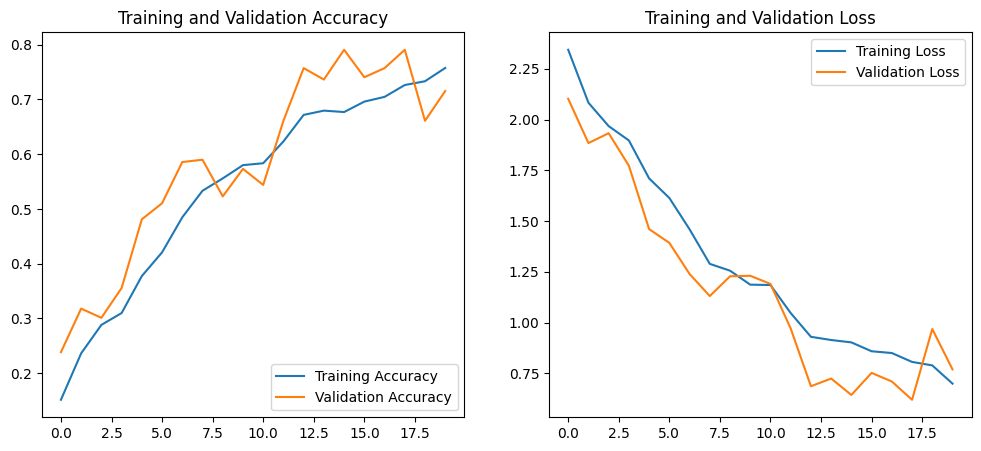


--- Classification Report ---
              precision    recall  f1-score   support

    Aloevera       0.73      0.85      0.79        26
        Amla       0.84      0.70      0.76        23
      Ashoka       0.92      1.00      0.96        23
 Ashwagandha       1.00      0.39      0.56        23
      Brahmi       0.95      0.78      0.86        23
       Gauva       0.56      0.61      0.58        23
       Henna       0.51      1.00      0.68        23
    Hibiscus       0.59      0.85      0.70        26
        Mint       0.76      0.92      0.83        24
        Neem       0.91      0.43      0.59        23
      Tulasi       1.00      0.48      0.65        23

    accuracy                           0.73       260
   macro avg       0.80      0.73      0.72       260
weighted avg       0.79      0.73      0.72       260



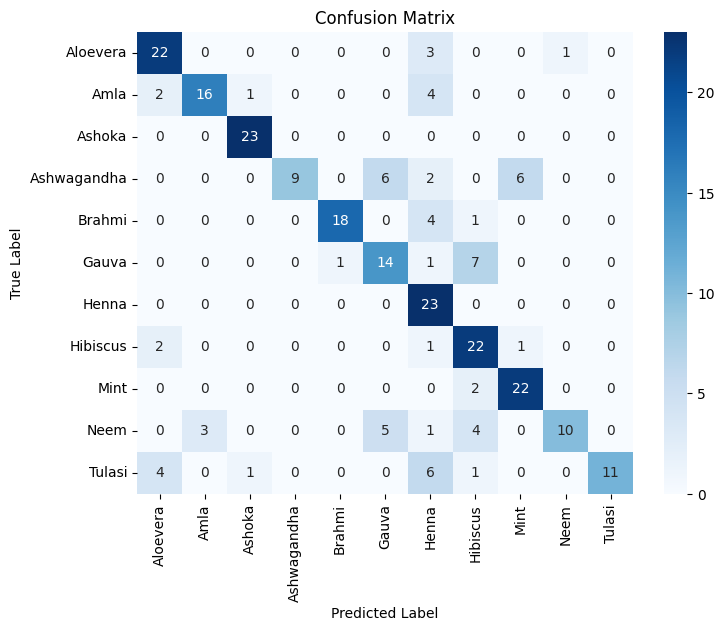

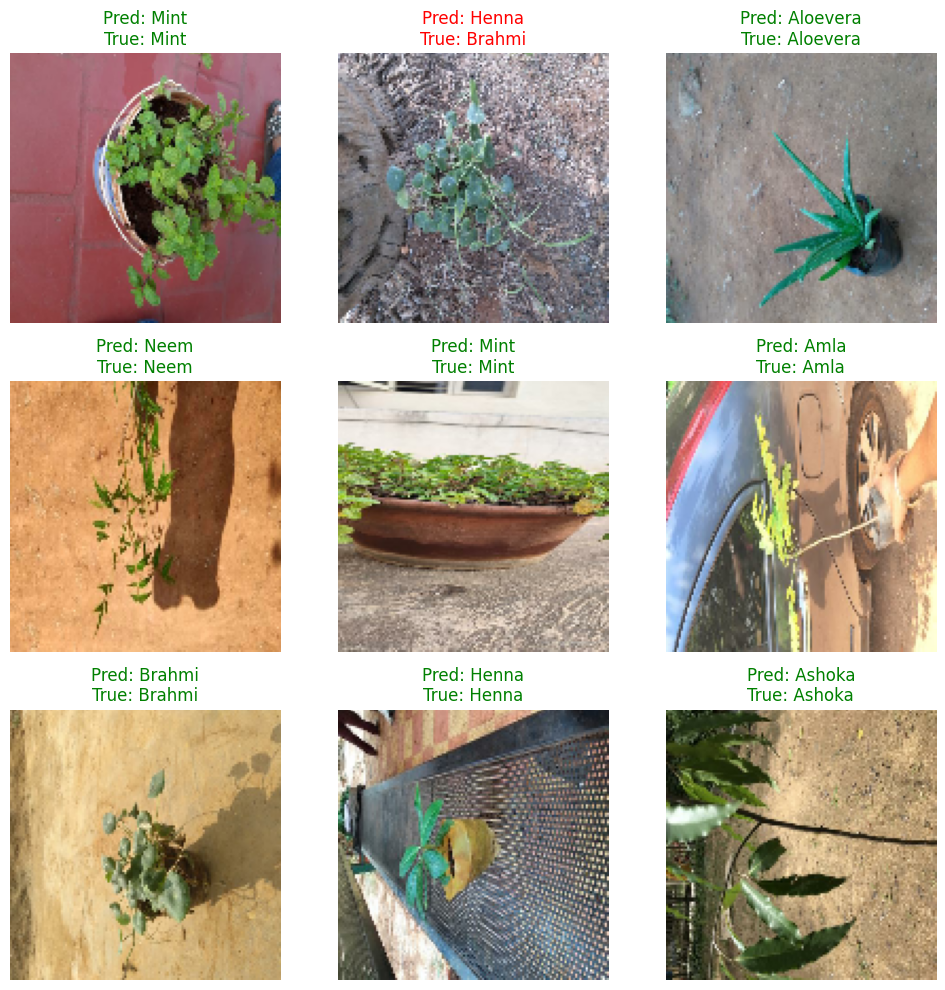

In [7]:
# 1. Accuracy and Loss Graphs
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']
epochs_range = range(EPOCHS)

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')

plt.savefig("/content/accuracy_loss_graph.png", dpi=300, bbox_inches='tight')
plt.show()

# 2. Classification Report & Confusion Matrix
y_true = []
y_pred = []

for images, labels in test_ds:
    preds = model.predict(images, verbose=0)
    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(preds, axis=1))

print("\n--- Classification Report ---")
print(classification_report(y_true, y_pred, target_names=class_names))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')

plt.savefig("/content/confusion_matrix.png", dpi=300, bbox_inches='tight')
plt.show()

# 3. Sample Prediction Grid (FIXED: Shuffles images across all classes)
plt.figure(figsize=(10, 10))

# Collect images across all batches and pick a random sample
all_test_images = []
all_test_labels = []

for images, labels in test_ds:
    all_test_images.append(images.numpy())
    all_test_labels.append(labels.numpy())

all_test_images = np.concatenate(all_test_images, axis=0)
all_test_labels = np.concatenate(all_test_labels, axis=0)

# Randomly select 9 indices from the entire dataset
random_indices = np.random.choice(len(all_test_images), size=9, replace=False)

sample_images = all_test_images[random_indices]
sample_labels = all_test_labels[random_indices]

# Run predictions on the random mix
preds = model.predict(sample_images, verbose=0)

for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(sample_images[i].astype("uint8"))

    pred_label = class_names[np.argmax(preds[i])]
    true_label = class_names[sample_labels[i]]

    color = "green" if pred_label == true_label else "red"
    plt.title(f"Pred: {pred_label}\nTrue: {true_label}", color=color)
    plt.axis("off")

plt.tight_layout()
plt.savefig("/content/sample_predictions.png", dpi=300, bbox_inches='tight')
plt.show()